# Active Crop Area ATBD
![NISAR Mission Logo](assets/NISAR_Mission_Logo.png)
![NISAR satellite rendering](assets/2022_NISAR_Beauty_02.png)
## Combined Algorithm Theoretical Basis Document and Jupyter Notebook for <br> *Active Crop Area*
### NASA ISRO Synthetic Aperture Radar Mission


Authors: Jessica Martinez, Alexandra Christensen, Paul Siqueira <br>
Microwave Remote Sensing Laboratory <br>
University of Massachusetts -- Amherst <br>
Date: 2025-02-11 <br>
Last updated: 2025-August <br>

## Summary
This notebook describes the Algorithm Theoretical Basis Document (ATBD) for generating an agricultural crop area product from NISAR time series data stacks. The algorithm is designed to meet the Level 2 Science requirements for detecting active crop area. This notebook constitutes a combination of formulating the theoretical basis for the NISAR active crop area algorithm that is based on the coefficient of variation and an implementation of the algorithm in executable python code.

This particular notebook contains two parts that are combined into one notebook.  These are
<ol>
    <li>The Coefficient of Variation (CV) Python code, and</li>
    <li>The USDA Cropland Data Layer (CDL)</li>
</ol>
Although not required to implement the NISAR Active Crop Area algorithm, the CDL is provided here to give an example how external data about the location of active crops can be used to optimally determine the threshold that can be applied to the CV for determining active crop area, and also used as a means for evaluating the algorithm.  For regions outside of the US (for example) where the CDL is not available, a similar landcover classification could be used, or one created from available optical data. <br>


<br>The NISAR requirement for Active Crop Area is: <br>

> *Requirement (L2-SCI-679):* <br> After the first year of operation, the NISAR Project shall measure crop area at 1-hectare resolution every 3 months with a classification accuracy of 80%.

## Overview of the Coefficient of Variation
Python code to implement coefficient of variation for crop/non-crop classification using a time series stack of SAR images. The notebook statistically calculates the CV across the time series stack and pixels in the resulting CV output are classified as “crop” or “non-crop” based on a threshold provided, or specified by the user. Pixels classified as water using a watermask derived from radar cross-section (RCS) values are removed prior to classification, due to the inherent variability of radar returns from water surfaces that make them inconsistent with the coefficient of variation (CV) patterns of non-cropland covers and prone to misclassification.

This notebook supports either the use of the USDA Cropland Data Layer (CDL) (which has been provided in the repository for use in this notebook) or external sources of labeled crop/non crop polygons which can be generated using high-resolution optical imagery of field-based methods such as windshield surveying. The labeled crop/non-crop validation data are used to calibrate and assess the classification threshold to improve classification results. The accuracy of the classification is evaluated against this data, and the results are exported as a Geotiff. 

**Coefficient of Variation is calculated by: Standard Deviation/Mean**

**Input datasets:**
- Timeseries of SAR imagery
- [USDA Cropland Data Layer](https://www.nass.usda.gov/research-and-science/cropland/sars1a)
  
##  Data Flow Diagram 
:::{figure} assets/NISAR_ATBD_crops_dataflow.png

:::

## New to Jupyter Notebooks?

Explore this [Project Pythia tutorial](https://foundations.projectpythia.org/foundations/jupyterlab-notebooks/) to learn the basics of working with notebooks.


## Software Environment
This notebook is supported by the `NISAR_Inundation` Conda/Mamba environment defined in the [../requirements.yml](../requirements.yml).

You can create the `nisar_croparea` environment with the following commands:
```bash
cd path/to/NISAR_CropArea
mamba env create -f requirements.yml
!mamba run -n nisar_croparea python -m ipykernel install --user --name nisar_croparea
```

<hr>

## Step 1: Import Python Packages

In [1]:
import copy
from datetime import date, datetime, UTC
import numpy as np
import os
from pathlib import Path
import warnings
import zipfile

import earthaccess
from IPython.display import display, HTML
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from osgeo import gdal
import pandas as pd
from pyproj import CRS
import rasterio
from rasterio.plot import show_hist
from rasterio.enums import ColorInterp
from rasterio.enums import Resampling
import rioxarray
import s3fs
from tqdm.notebook import tqdm
import xarray as xr 

from util.wkt import rectangular_aoi_select, rectangular_wkt_bounds
from util.util import nisar_start_time_from_url
from util.aoi_coverage import plot_aoi_coverage

gdal.UseExceptions()

warnings.filterwarnings(
    "ignore",
    category=FutureWarning,
    module=r"earthaccess.*"
)

<hr>

## Step 2: Initialize All User-Defined Notebook Variables

There are two ways to run this notebook:
- Step through it in JupyterLab, running each code cell.
- Run it as a Python script from the command line using `papermill`.

[papermill](https://github.com/nteract/papermill) is a tool that allows you to parameterize and execute a Jupyter Notebook as a script. This notebook has been configured so that it may be executed manually in JupyterLab by running code cells or from the command line, as a script, using papermill.

:::{hint}
#### papermill command examples:

Run the CalVal data demo from the command line:
```
papermill NISAR_L3_CropArea_ProductGeneration.ipynb NISAR_L3_CropArea_ProductGeneration_papermill_demo_output.ipynb \
-p papermill True \
-p demo True \
-p study_area tifton
```

Run on GCOV data for a user-defined AOI and time range (This requires that your Earthdata Login credentials are added to a `~/.netrc` file or as environment variables):
```
papermill NISAR_L3_CropArea_ProductGeneration.ipynb NISAR_L3_CropArea_ProductGeneration_papermill_data_search_output.ipynb \
-p papermill True \
-p demo False \
-p subset_wkt "POLYGON((-91.624689 18.263099, -91.38299 18.263099, -91.38299 18.432551, -91.624689 18.432551, -91.624689 18.263099))" \
-p start_dt "2025-08-01 00:00:00" \
-p end_dt "2026-02-01 23:59:59" \
-p granule_name "*_D_*_DHDH_*" \
-y "tracks: []" \
-y "frames: []"
```
:::

### Step 2a: Initialize Crop Area workflow parameters

:::{warning} TODO: Update info on demo data.

Leaving the `demo` argument below set to `True` will process an example dataset.

The time-series of SAR images is nominally meant to be downloaded from an instrument data archive. The time series stack provided in the repository has already been co-registered for the area of interest. This data is NISAR-simulated from ALOS-1 PALSAR data to serve as an example pre-launch. 

**The NISAR mission will measure crop area every 3 months, for which CV is caculated within the bracketed dates of:**  <br>
- January 1 - March 31<br>
- April 1- June 30 <br>
- July 1- September 30 <br>
- October 1- December 31 <br>
-in addition to the entire year. <br>


**Selection of which images to include in the time series stack can capture one of these three month periods or use all avaliable scenes. For the demo, the pre-determined threshold for Tifton evaulates all avaliable time series dates within the 2022 year.** 

:::

:::{hint}
Update the arguments below and in Step 2c to define and process your own NISAR GCOV dataset
:::

In [2]:
papermill = False # Set to False when executing the notebook manually. Set to True when executing from the command line with papermill (see examples above)
demo = True # Set to True to example Tifton, GA data. Set to False to request NISAR data in your AOI
study_area = 'tifton' # 'tifton' for demo Tifton, GA data
which_pol = 'HHHH'
cv_threshold = 0.4 # 0.4 for demo Tifton, GA data

### Step 2b: (Optional) Draw an AOI on a Map to Generate Well-Known-Text for Spatial Subsetting

If you are generating inundation maps from a custom stack of GCOV data, you must define a spatial subset in Step 2c using a Well-Known-Text (WKT) POLYGON. 

The interactive map produced below allows you to generate WKT for an AOI, which you can copy and paste into Step 2c's `subset_wkt` variable. 

If you are running the demo cal-val dataset or already have the WKT for your AOI, you can skip Steps 2b and 2c. Running them will not process or display anything.

In [3]:
if not demo and not papermill:
    aoi_map = rectangular_aoi_select()
    display(aoi_map["map"])

### Step 2c: If Processing a Custom-Defined Stack of GCOV Data, Overwrite the Default Search and Subset Variables Below

:::{hint} Leave `tracks` and `frames` as empty lists for an initial data search to view all tracks and frames that intersect your AOI

```
    tracks = []
    frames = []
```

Results in multiple track and frames may intersect your AOI. Some may have little or no valid data coverage for your AOI. You can filter the results by track and frame to remove them.

If you don't already know the tracks/frames you want, run an unfiltered search. Step 3a performs a search and displays every track/frame intersecting your AOI. You can then add the tracks and frames you wish to keep to the lists below and rerun the search.
:::

In [4]:
if not demo and not papermill:
    subset_wkt = "POLYGON((-83.761482 40.969789, -82.970467 40.969789, -82.970467 41.49855, -83.761482 41.49855, -83.761482 40.969789))"
    start_dt = '2026-07-01 00:00:00'
    end_dt = '2026-10-15 23:59:59'
    granule_name = '*_DHDH_*' # GCOV product ID search filter
    tracks = []
    frames = []

<hr>

## Step 3: Access the Data

Download NISAR Ecosystems Inundation demonstration data from its S3 bucket or access NISAR GCOV data with `earthaccess` 

### Step 3a: Search for Data

In [5]:
%%time

if demo:
    gcov_url = f's3://nisar-public-ebd/ATBD/ecosystems/croparea/sites/{study_area}/*/*/*'
    s3 = s3fs.S3FileSystem(anon=True,endpoint_url='https://s3.us-west-1.wasabisys.com')
    gcov_paths = ['s3://' + k  for k in s3.glob(gcov_url)]
    # gcov_paths = gcov_paths[:3] # Comment out this line if you wish to process all demo scenes
else:
    subset_bounds = rectangular_wkt_bounds(subset_wkt)
    bbox = dict(
        minx=float(subset_bounds["west"]), 
        miny=float(subset_bounds["south"]), 
        maxx=float(subset_bounds["east"]), 
        maxy=float(subset_bounds["north"]), 
        crs="EPSG:4326")
    temporal = (start_dt, end_dt)
    kwargs = {
        'granule_name': granule_name,
        'bounding_box': (bbox["minx"], bbox["miny"], bbox["maxx"], bbox["maxy"]),
        'temporal': temporal,
        'short_name': 'NISAR_L2_GCOV_PROVISIONAL_V1'
    }
    auth = earthaccess.login()
    results = earthaccess.search_data(**kwargs)

    tracks = [int(t) for t in tracks]
    frames = [int(f) for f in frames]
    results = [r for r in results
               if (len(tracks) == 0 or int(r["umm"]["AdditionalAttributes"][-1]["Values"][0]) in tracks)
               and (len(frames) == 0 or int(r["umm"]["AdditionalAttributes"][1]["Values"][0]) in frames)]

    if not results:
        raise Exception("Search returned no results")
        
    gcov_paths = [r.data_links(access='direct')[0] for r in results]

    gpolygons = [r['umm']['SpatialExtent']['HorizontalSpatialDomain']['Geometry']['GPolygons'][0] for r in results]
    results_tracks = [r["umm"]["AdditionalAttributes"][-1]["Values"][0] for r in results]
    results_frames = [r["umm"]["AdditionalAttributes"][1]["Values"][0] for r in results]
    results_orbit_direction = [r["umm"]["AdditionalAttributes"][0]["Values"][0].lower() for r in results]

    print(f"Number of scenes in search results: {len(gcov_paths)}\n")
    track_frame_strings = [f"  - track: {g[0]}, frame: {g[1]} ({g[2]})" for g in list(set(zip(results_tracks, results_frames, results_orbit_direction)))]
    print(f"Search result track/frames:")
    for tf in track_frame_strings:
        print(tf)

    display(plot_aoi_coverage(gpolygons, subset_wkt, results_tracks, results_frames, results_orbit_direction))
    
gcov_paths = sorted(gcov_paths)

CPU times: user 54.7 ms, sys: 20.7 ms, total: 75.4 ms
Wall time: 428 ms


### Step 3b: Load the Data

In [6]:
%%time

group_path = "/science/LSAR/GCOV/grids/frequencyA" # change this to any GCOV HDF5 group you wish

if demo:
    kwargs = {
        "cache_type": "background",
        "block_size": 8 * 1024 * 1024,  # 8 MB
    }
    s3_files = [s3.open(url, "rb", **kwargs) for url in gcov_paths]
    datatrees = [
        xr.open_datatree(
            f,
            engine="h5netcdf",
            decode_timedelta=False,
            phony_dims="access",
            chunks="auto",
            group=group_path,
        )
        for f in s3_files
    ]
else:
    files = earthaccess.open(results)
    access_type = "direct S3" if type(files[0].fs) == s3fs.core.S3FileSystem else "external HTTPS"
    print(f"Using earthaccess {access_type} access") 
    datatrees = [
        xr.open_datatree(
            f,
            engine="h5netcdf",
            decode_timedelta=False,
            phony_dims="access",
            chunks="auto",
            group=group_path,
        )
        for f in files
    ]

CPU times: user 1.12 s, sys: 329 ms, total: 1.44 s
Wall time: 4.71 s


### Step 3c: Create a Time Series xarray.Dataset

:::{warning} Slow step
This step streams the spatially subset data to memory. It may take some time, depending on the size of your dataset and the amount of available memory.
:::

In [7]:
%%time

datetimes = [nisar_start_time_from_url(gcov_path) for gcov_path in gcov_paths]
product_ids = [Path(pth).stem for pth in gcov_paths]

dataarrays = []

for dt, pid, tree in zip(datetimes, product_ids, datatrees):
    ds = tree.ds[
        ['HHHH', 'HVHV', 'projection', 'xCoordinateSpacing', 'yCoordinateSpacing']
    ]

    ds = ds.expand_dims(time=[dt])
    ds = ds.assign_coords(product_id=("time", [pid]))

    dataarrays.append(ds)

for i, da in enumerate(dataarrays):
    da = da.rio.write_crs(f"EPSG:{da.projection.item()}")
    if not demo:
        dataarrays[i] = da.rio.clip_box(**bbox)

ts = xr.concat(dataarrays, dim="time")
ts = ts.persist()
ts

CPU times: user 1.09 s, sys: 311 ms, total: 1.4 s
Wall time: 1.23 s


<xarray.Dataset> Size: 185MB
Dimensions:             (time: 10, yCoordinates: 1677, xCoordinates: 1378)
Coordinates:
  * time                (time) datetime64[us] 80B 2022-01-25T05:33:57 ... 202...
    product_id          (time) <U91 4kB 'NISAR_L2_PR_GCOV_001_001_A_000_2000_...
  * yCoordinates        (yCoordinates) float64 13kB 3.517e+06 ... 3.484e+06
  * xCoordinates        (xCoordinates) float64 11kB 2.353e+05 ... 2.628e+05
Data variables:
    HHHH                (time, yCoordinates, xCoordinates) float32 92MB dask.array<chunksize=(1, 1677, 1378), meta=np.ndarray>
    HVHV                (time, yCoordinates, xCoordinates) float32 92MB dask.array<chunksize=(1, 1677, 1378), meta=np.ndarray>
    projection          (time) uint32 40B 32617 32617 32617 ... 32617 32617
    xCoordinateSpacing  (time) float64 80B 20.0 20.0 20.0 ... 20.0 20.0 20.0
    yCoordinateSpacing  (time) float64 80B -20.0 -20.0 -20.0 ... -20.0 -20.0

### Step 3d: Confirm That All Data Are Projected to the Same EPSG

In [8]:
epsgs = [ts.sel(time=t).rio.crs.to_epsg() if dataarrays[0].projection.item() == 0 else dataarrays[0].projection.item() for t in ts.time]
epsg_equal = len(set(epsgs)) == 1
if epsg_equal:
    print(f"Time series contains single EPSG: {epsgs[0]}")
else:
    raise Exception(f"Time series contains multiple EPSGs: {set(epsgs)}")

num_files = len(ts.time)

Time series contains single EPSG: 32617


<hr>

## Step 4: Plot the Time Series

### Step 4a: Plot the HHHH and HVHV Data


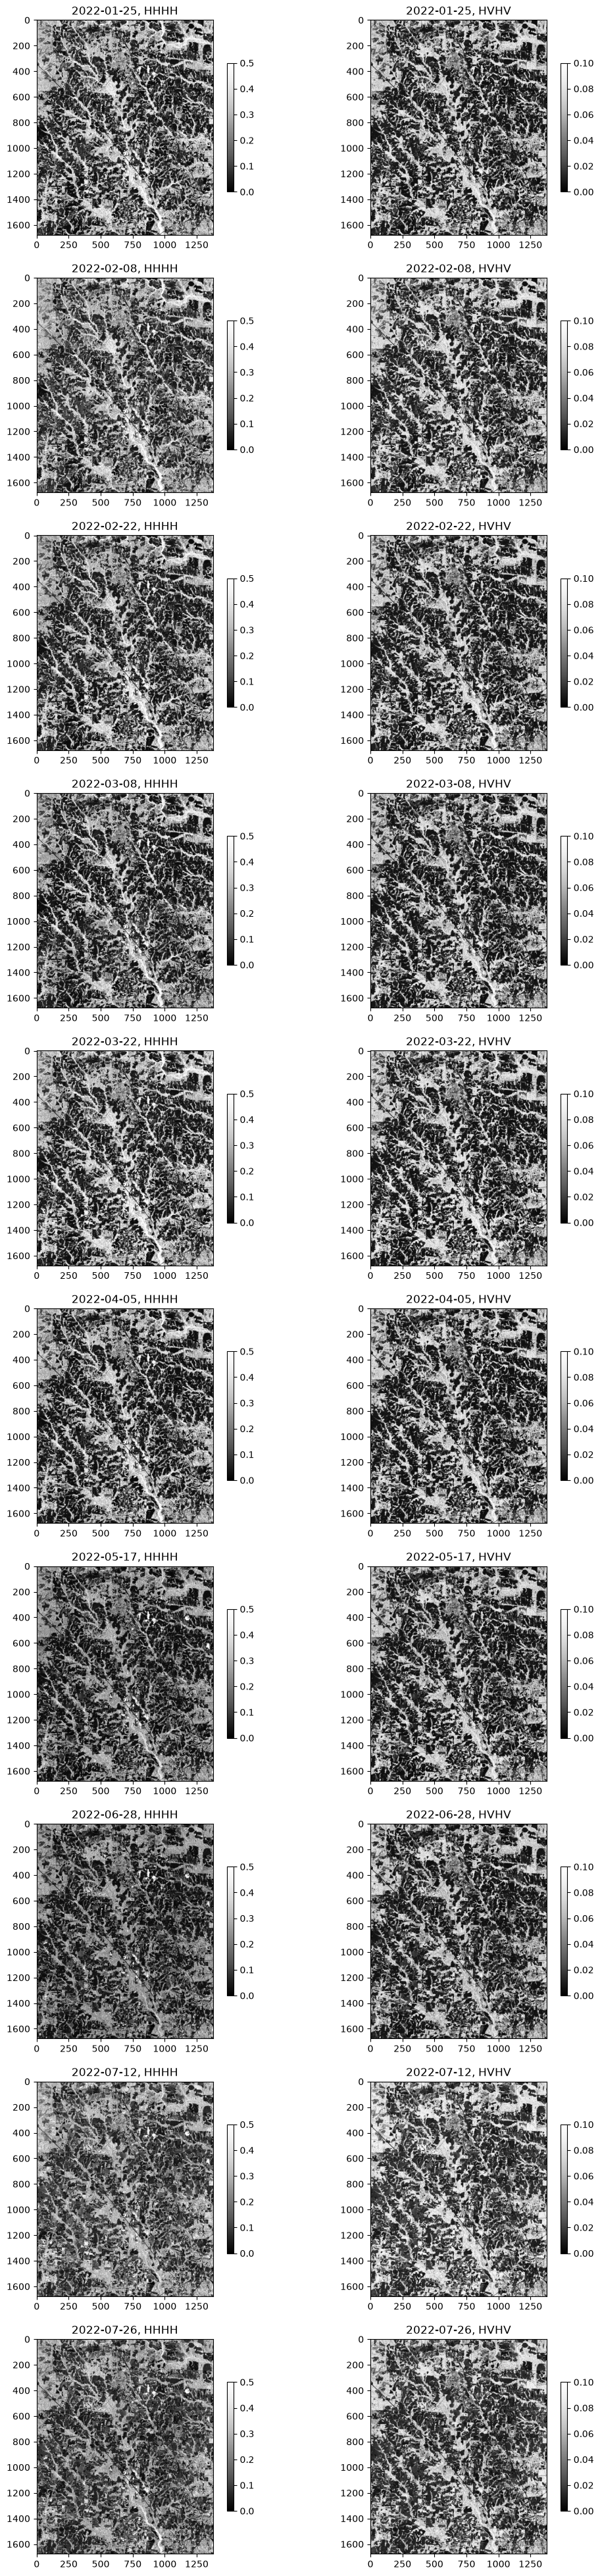

In [9]:
# plot the GCOV images
fig, axs = plt.subplots(num_files, 2, figsize=(12,num_files*5), squeeze=False)
cbar_shrink = 0.6
cmp = plt.get_cmap('Greys_r')

for i, t in enumerate(ts.time):
    step = max(1, int(np.ceil(max(ts.sizes["yCoordinates"], ts.sizes["xCoordinates"]) / 2000)))
    im1 = axs[i][0].imshow(ts.sel(time=t).HHHH[::step, ::step], vmin=0, vmax=0.5, cmap=cmp)
    title_str = f"{str(ts.sel(time=t).time.item().date())}, HHHH"
    axs[i][0].set_title(title_str)
    fig.colorbar(im1, ax=axs[i][0], shrink=cbar_shrink)

    im2 = axs[i][1].imshow(ts.sel(time=t).HVHV[::step, ::step], vmin=0, vmax=0.1, cmap=cmp)
    title_str = f"{str(ts.sel(time=t).time.item().date())}, HVHV"
    axs[i][1].set_title(title_str)
    fig.colorbar(im2, ax=axs[i][1], shrink=cbar_shrink)

<hr>

## Step 5: Generate a Water Mask

This section generates a watermask from the Radar Cross Section (RCS) values across the observed time series. Water has a high variation measurement not comparable to the CV values of other non-cropland land covers and is often misclassified because of this. Through implementation of a threshold based approach, pixels in the time series stack are classified as water if their RCS value is equal to or below the user-defined threshold more than 75% of the time (across the time series stack), ensuring that the high variation of water remains accounted for to reduce the risk of potential misclassification.  <br>

:::{attention} A note about generating a high quality water mask
Generation of the RCS watermask will require some investigation of scene statistics as well as visual inspection of the time series stack for adequate selection of a threshold. Water bodies are typically visually notable in SAR imagery, due to the nature for which they interact with the microwave pulses transmitted by the SAR system (i.e. NISAR). Water typically behaves similarly to a mirror when recieving the transmitted pulses, reflecting the energy away from the sensor. Thus, since the recieved pulse is reflected away, very little signal reflects directly back to the sensor, resulting in distinguisably lower backscatter values and a visually darker presence in the image compared to neighboring and surronding land cover.

The threshold for distinguising water pixels will vary depending both on the SAR imagery used and the temporal period of the time series stack. A very loose reference RCS reference range for water is -15 dB to -30 dB, with the understanding that the threshold value may end up being outside of this range. 

:::

### Step 5a: Convert Data From dB to Power for Plotting

In [10]:
power_arr = ts[which_pol]
db_arr = 10 * np.log10(power_arr)

### Step 5b: Plot the RCS Histogram in dB

Values in dB:
Pixel Standard Deviation: Min = -24.506763, Max = 26.71462, Mean = -9.283604


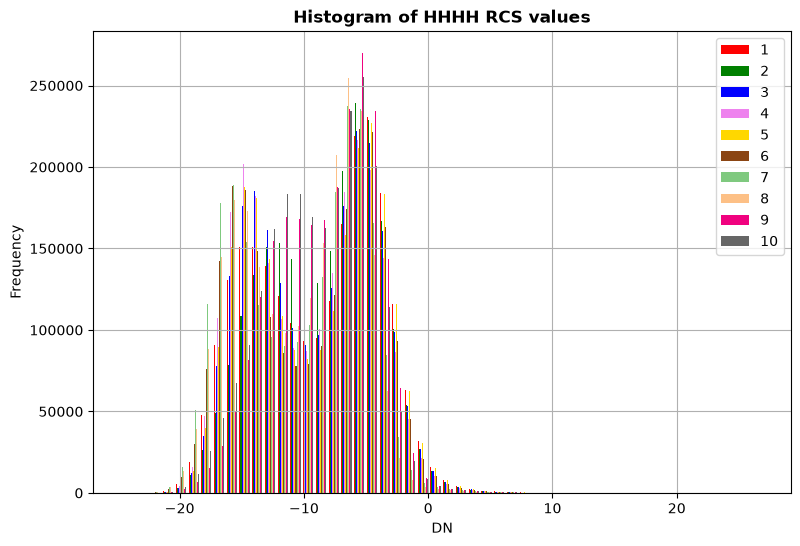

In [11]:
# Peaks in the RCS histogram can be referenced for selection of the watermask threshold 
print('Values in dB:')
print("Pixel Standard Deviation: Min = %s, Max = %s, Mean = %s" %(round(np.nanmin(db_arr),6),round(np.nanmax(db_arr),6),round(np.nanmean(db_arr),6)))

plt.figure(figsize = (9,6))
show_hist(db_arr.values, bins = 50, title = "Histogram of %s RCS values" %(which_pol))  # this is the only routine that uses rasterio


### Step 5c: Generate the Water Mask

Number of water pixels: 31706
Number of pixels for classification: 2279200
Water pixels are marked as blue


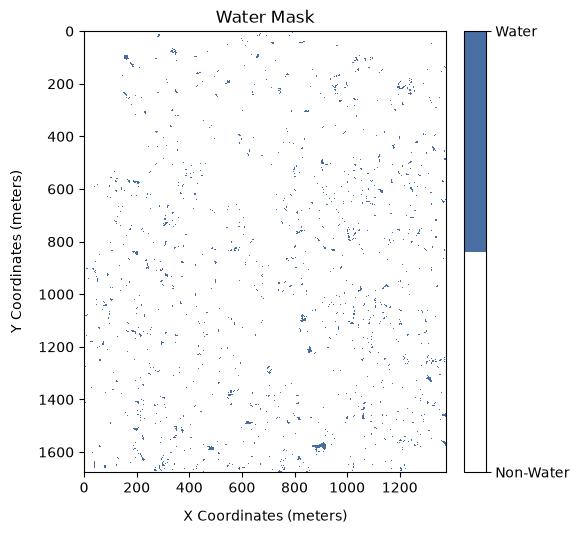

In [12]:
# define RCS threshold and reclassify time series based on threshold
water_number = 111
water_thresh = -16.5
masked_ts_stack = xr.where(db_arr <= water_thresh, 1, 0)

# aggregate the water mask over time, if a pixel is classified as water based on the threshold used at least 75% of the time, 
# it is classified as water across the entire time series stack 
rcs_watermask = (masked_ts_stack.sum("time") > db_arr.sizes["time"] * 0.75).astype(int)

# reclassify the watermask to match the classification values of the CDL (water= 111)
watermask = xr.where(rcs_watermask == 1, water_number, rcs_watermask)

# get the number of pixels masked and not masked
rcs111 = int((watermask == water_number).sum().compute())
print("Number of water pixels:", rcs111)

rcs0 = int((watermask == 0).sum().compute())
print("Number of pixels for classification:", rcs0)

# visually inspect the watermask, and adjust threshold if needed
fig, ax = plt.subplots(figsize = (5,5))
fig.tight_layout()
watermask_cmap = plt.cm.colors.ListedColormap(["#ffffff", "#496fa2"])
cax = ax.imshow(watermask, interpolation ='nearest', cmap = watermask_cmap)
ax.set_title("Water Mask")
cbar = fig.colorbar(cax, ticks = [0,111], fraction = 0.046 * watermask.shape[0] / watermask.shape[1],pad = 0.04)
cbar.ax.set_yticklabels(['Non-Water', 'Water'])
plt.ylabel('Y Coordinates (meters)', labelpad=10)
plt.xlabel('X Coordinates (meters)', labelpad=10)
print('Water pixels are marked as blue')

<hr>

## Step 6: Calculate the Coefficient of Variation

### 6.1 Calculating the CV on the SAR Timeseries Stack

:::{note} The equation for the Coefficient of Variation (CV)

$$
CV = \frac{\sigma}{\mu}
$$

Where:
- $\sigma$ (sigma) = standard deviation
- $\mu$ (mu) = mean
:::

In [13]:
try:
    # Calculate the mean for the time stack of images
    mean = power_arr.mean("time")
    
    # Calculate the standard deviation for the time stack of images
    std = power_arr.std("time")
    
    # Calculate the coefficient of variation for the time stack of images 
    cv = (std/mean)

    print('✅ CV successfully caculated')
except ValueError as e:
    print('caculation of CV failed', e)

✅ CV successfully caculated


<hr>

## Step 7: Plot Mean, Standard Deviation, and CV of the Time Series

### Step 7a: Plot the Histogram of the CV 

Pixel Standard Deviation: Min = 0.000683, Max = 64.9036, Mean = 0.065013
Pixel Coefficient of Variation: Min = 0.019923, Max = 2.968073, Mean = 0.354387


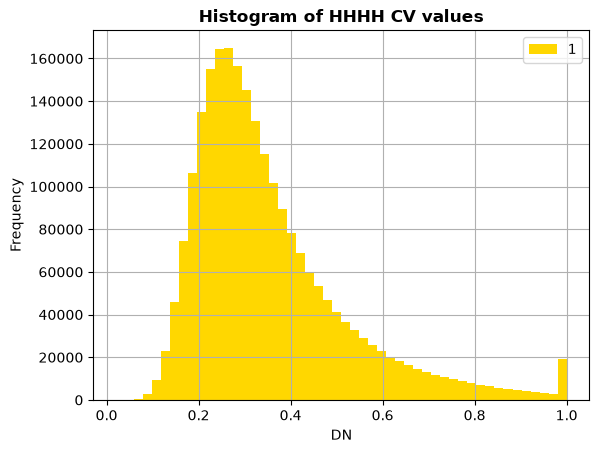

In [14]:
print("Pixel Standard Deviation: Min = %s, Max = %s, Mean = %s" %(round(np.nanmin(std),6),round(np.nanmax(std),6),round(np.nanmean(std),6)))
print("Pixel Coefficient of Variation: Min = %s, Max = %s, Mean = %s" %(round(np.nanmin(cv),6),round(np.nanmax(cv),6),round(np.nanmean(cv),6)))

show_hist(np.clip(cv.values,0,1),bins = 50,title = "Histogram of %s CV values" %(which_pol))  


### Step 7b: Plot the Mean RCS (dB)

Text(0.5, 1.0, 'Mean of Radar-Cross Section (dB)')

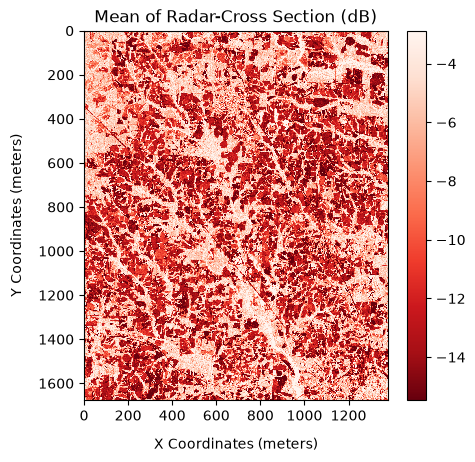

In [15]:
mean_db = 10*np.log10(mean)

vmin, vmax = mean_db.quantile([0.05, 0.95]).values

plt.set_cmap('Reds_r')
plt.rcParams['figure.figsize'] = (20,5)
plt.imshow(mean_db, vmin = vmin, vmax = vmax, interpolation ='nearest');
plt.colorbar(fraction = 0.046*mean.shape[0] / mean.shape[1], pad = 0.04);
plt.ylabel('Y Coordinates (meters)', labelpad=10)
plt.xlabel('X Coordinates (meters)', labelpad=10)
plt.title('Mean of Radar-Cross Section (dB)')

### Step 7b: Plot the Standard Deviation of the RCS

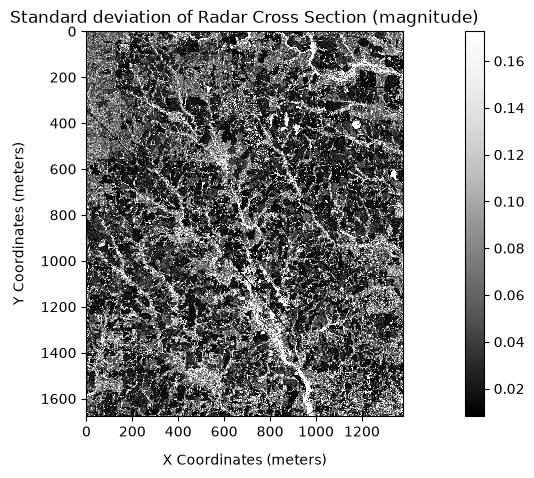

In [16]:
vmin, vmax = std.quantile([0.05, 0.95]).values

plt.imshow(std.values, vmin=vmin, vmax=vmax, interpolation='nearest', cmap='Greys_r');
plt.colorbar(fraction = 0.046*std.shape[0]/std.shape[1], pad=0.04);
plt.ylabel('Y Coordinates (meters)', labelpad=10)
plt.xlabel('X Coordinates (meters)', labelpad=10)
plt.title('Standard deviation of Radar Cross Section (magnitude)');

### Step 7c: Plot the CV

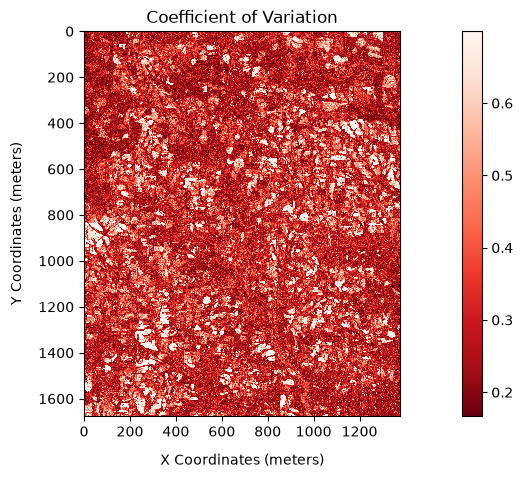

In [38]:
vmin, vmax = cv.quantile([0.05, 0.95]).values

plt.imshow(cv.values, vmin=vmin, vmax=vmax, interpolation='nearest', cmap='Reds_r');
plt.colorbar(fraction = 0.046*cv.shape[0] / cv.shape[1], pad=0.04);
plt.ylabel('Y Coordinates (meters)', labelpad = 10)
plt.xlabel('X Coordinates (meters)', labelpad = 10)
plt.title('Coefficient of Variation');

<hr> 

## Step 8: Export the CV to GeoTIFF

### Step 8a: Create Directories for Input, Ancillary, and Output Data

In [35]:
start = ts.time[0].item().strftime("%Y%m%d")
end = ts.time[-1].item().strftime("%Y%m%d")

crop_area_root_dir = Path.cwd() / "crop_area_classifications"

project_dir = crop_area_root_dir / f"{study_area}_{start}_{end}"
project_dir.mkdir(parents=True, exist_ok=True)

crop_dir = project_dir / "crops"
crop_dir.mkdir(parents = True, exist_ok = True)
gcov_dir = project_dir / "GCOV"
gcov_dir.mkdir(parents = True, exist_ok = True)
tmp_dir = project_dir / "tmp"
tmp_dir.mkdir(parents = True, exist_ok = True)
ancillary_data_dir = crop_area_root_dir / "ancillary_data"
ancillary_data_dir.mkdir(parents = True, exist_ok = True)

### Step 8b: Write the CV

In [39]:
scene = ts.isel(time=0)
width = scene.xCoordinates.shape[0]
height = scene.yCoordinates.shape[0]
transform = scene.rio.transform()
epsg = scene.projection.item()
scene = scene.rio.write_crs(f"EPSG:{epsg}") 
crs = scene.rio.crs
x_posting = transform[0]
y_posting = transform[0]
minx = scene.xCoordinates[0]
miny = scene.yCoordinates[0]
maxx = scene.xCoordinates[-1]
maxy = scene.yCoordinates[-1]

meta = {'driver': 'GTiff', 
        'dtype': 'float32', 
        'nodata': 0, 
        'width': width, 
        'height': height, 
        'count': 1, 
        'crs': crs, 
        'transform': transform,
        'tiled': True,
        "driver": "COG",
        "compress": "LZW",   # Apply LZW compression
        "blockxsize": 512,   # Tile size
        "blockysize": 512,
        "overviews": [2, 4, 8, 16],  # Pyramid overviews
        "BIGTIFF": "YES",
        'interleave': 'band'}


cv_path = crop_dir / f"NISAR_CropArea_CV_{str(which_pol[:-2])}_{start}_{end}_{study_area}.tif"

try: 
    with rasterio.open(cv_path, 'w', **meta) as dst:
        dst.write(cv.values, indexes = 1)  
        print(f"✅ CV successfully written: {cv_path}")
except Exception as e:
    print(f'An error occured: {e}')

✅ CV successfully written: /home/jovyan/NISAR_CropArea_Fork/NISAR_CropArea/notebooks/crop_area_classifications/tifton_20220125_20220726/crops/NISAR_CropArea_CV_HH_20220125_20220726_tifton.tif


<hr>

## Step 9: Generate the L3 Crop Area Product

### Step 9.1: Review the Threshold to Classify Crop Area 


| CV value                         | Class        |
|----------------------------------|--------------|
| CV pixel value ≥ threshold       | **crop**     |
| CV pixel value< threshold        | **non-crop** |


:::{note} A note about the threshold for the Tifton, GA example data
The pre-calibrated threshold for the example Tifton, GA data is `0.4`

The ideal threshold was derived by [Youden's J-Index](https://en.wikipedia.org/wiki/Youden%27s_J_statistic), a summary measure representing the maximum difference between the true positive rate and false positive rate between the Coefficient of Variation and the validation source (i.e the [CDL](https://www.nass.usda.gov/research-and-science/cropland/sars1a)). 

While the ROC curve technique offers a statistical guidance to a threshold with discriminatory ability between crop area and non-crop area, users can also provide their own threshold from a "guess and check" approach. 
:::

In [40]:
print(f"cv_threshold: {cv_threshold}") # The cv_threshold value was set in Step 2a

cv_threshold: 0.4


##### 

### Step 9.2: Create Crop/Non-Crop/Water Classification Map

In [41]:
#Classify image using the Youden's Index Optimal Threshold
cv_reclass_ideal = xr.where(cv >= cv_threshold, 1, 0)

# apply watermask to classified result, setting water pixel values to 3
cv_reclass_ideal_water_masked = xr.where(watermask == 111, 3, cv_reclass_ideal)
cv_reclass_ideal_water_masked

<xarray.DataArray 'HHHH' (yCoordinates: 1677, xCoordinates: 1378)> Size: 18MB
dask.array<where, shape=(1677, 1378), dtype=int64, chunksize=(1677, 1378), chunktype=numpy.ndarray>
Coordinates:
  * yCoordinates  (yCoordinates) float64 13kB 3.517e+06 3.517e+06 ... 3.484e+06
  * xCoordinates  (xCoordinates) float64 11kB 2.353e+05 2.353e+05 ... 2.628e+05

### Step 9.3: Visually Inspect the Classification Before Downsampling and Exporting

Crop pixels marked in yellow


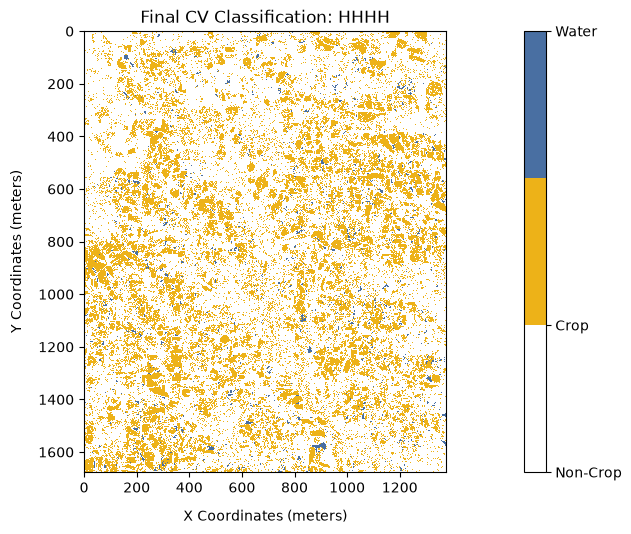

In [42]:
fig, ax = plt.subplots(figsize = (20,5))
fig.tight_layout()
l3_cmap = plt.cm.colors.ListedColormap(["#ffffff", "#EDB218", "#496fa2"])
cax = ax.imshow(cv_reclass_ideal_water_masked, interpolation = 'nearest', cmap = l3_cmap)
ax.set_title('Final CV Classification: %s' %(which_pol))
cbar = fig.colorbar(cax, ticks = [0,1,3], fraction = 0.046 * cv_reclass_ideal_water_masked.shape[0] / cv_reclass_ideal_water_masked.shape[1],pad = 0.04)
cbar.ax.set_yticklabels(['Non-Crop', 'Crop', 'Water'])
plt.ylabel('Y Coordinates (meters)', labelpad = 10)
plt.xlabel('X Coordinates (meters)', labelpad = 10)

print('Crop pixels marked in yellow')

<hr>

## Step 10 Downsample and Export the Classified Image

- Downsample to 1 Ha resolution
- Export final L3 classification product (native resolution and 1 Ha)

Writes the array to a geotiff that is classified by the Youden's Index ideal threshold based on CV to the set output directory. 

In [ ]:

classified_20m_prefix = "%s_%s_%s_20m_classification.tif" %(study_area, str(which_pol[:-2]), today)
L3_prefix = "NISAR_L3_%s_40_A_CROP_%s_%s_%s_001_%s.tif" %(str(which_pol[:-2]), l3_start_date, l3_end_date, study_area, today)
print(classified_20m_prefix)
print(L3_prefix)

In [ ]:
# reclassify the classified image to match the proper crop l3 classification values 
# where: non_crop = 1, crop = 2, water =3

l3_CV_reclass_ideal_w_h20= np.copy(CV_reclass_ideal_w_h20)
l3_CV_reclass_ideal_w_h20[CV_reclass_ideal_w_h20 == 0] = 1
l3_CV_reclass_ideal_w_h20[CV_reclass_ideal_w_h20 == 1] = 2
print(np.unique(l3_CV_reclass_ideal_w_h20))

In [ ]:
with rasterio.open(TMP_dir / classified_20m_prefix, 'w', **meta) as dst:
    dst.write(l3_CV_reclass_ideal_w_h20,indexes = 1)  
   
fig, ax = plt.subplots(figsize=(20,5))
fig.tight_layout()
cax = ax.imshow(CV_reclass_ideal_w_h20, interpolation = 'nearest', cmap = l3_cmap)
ax.set_title('Classified Crop/Non-Crop Area (20m resolution) ')
cbar = fig.colorbar(cax, ticks = [0,1,3], fraction = 0.046 * CV_reclass_ideal_w_h20.shape[0] / CV_reclass_ideal_w_h20.shape[1],pad = 0.04)
cbar.ax.set_yticklabels(['Non-Crop', 'Crop', 'Water'])
plt.ylabel('Y Coordinates (meters)', labelpad = 10)
plt.xlabel('X Coordinates (meters)', labelpad = 10)


print('Crop pixels marked in yellow (Non-crop = 1, Crop = 2, Water = 3')


## 3.7 &emsp; Downsample to the hectare scale for generation of the final L3 crop area product 

In [ ]:
classified_20m_files = sorted(glob.glob(str(TMP_dir / classified_20m_prefix)))
for file in classified_20m_files:
    classified_20m_filename = str(file)
    classified_20m_file = gdal.Open(classified_20m_filename)
    print(classified_20m_filename)

try:
    gdal.Warp(str(study_area_dir / L3_prefix), classified_20m_file, xRes = 100, yRes = 100, resampleAlg ='near', format = 'GTIFF')
    #os.remove(str(TMP_dir/classified_20m_filename))
    print("✅ Success!")
except Exception as e:
    print('An error occured: {e}')

In [ ]:
L3_product_file = glob.glob(str(study_area_dir / L3_prefix))
for file in L3_product_file:
    L3_product = str(file)
    croparea_L3_classification = gdal.Open(L3_product).ReadAsArray()

fig, ax = plt.subplots(figsize=(10,10))
fig.tight_layout()
cax = ax.imshow(croparea_L3_classification, interpolation ='nearest', cmap = l3_cmap)
ax.set_title('Classified Crop/Non-Crop Area (1 Ha resolution)')
cbar = fig.colorbar(cax, ticks = [0,1,3], fraction = 0.046*croparea_L3_classification.shape[0] / croparea_L3_classification.shape[1], pad = 0.04)
cbar.ax.set_yticklabels(['Non-Crop', 'Crop', 'Water'])
plt.ylabel('Y Coordinates (meters)', labelpad = 10)
plt.xlabel('X Coordinates (meters)', labelpad = 10)

print('Crop pixels marked in yellow (Non-crop = 1, Crop = 2, Water = 3')


In [ ]:
 ## A statistical summary of the number of Crop and Non-Crop pixels from the crop/non-crop classification 

l3_cropcount = np.count_nonzero(croparea_L3_classification == 2)
l3_noncount = np.count_nonzero(croparea_L3_classification == 1)
l3_watercount = np.count_nonzero(croparea_L3_classification == 3)
l3_nodata_count = np.count_nonzero(croparea_L3_classification == 0)

total = np.count_nonzero(croparea_L3_classification != 0)

# finding the percent of pixels classified as crop area, non-crop area and water
percent_l3_crop = round((l3_cropcount / total) * 100,2)
print('% Crop',percent_l3_crop)
percent_l3_noncrop = round((l3_noncount / total) * 100, 2)
print('% Non-Crop',percent_l3_noncrop)
percent_l3_water = round((l3_watercount/total) * 100,2)
print('% Water', percent_l3_water)
percent_l3_nodata = round((l3_nodata_count/total) * 100,2)
print('% No Data', percent_l3_nodata)


### **set up metadata parameters**

In [ ]:
sar_array = []
for ii in indices2:
    if demo:
        fp = all_GCOV_data[ii].split('/')[-1]
    else:
        fp = all_GCOV_data[ii].path.split('/')[-1]
    sar_array.append(fp)


In [ ]:
first_nisar_date = str(sar_array[0])
last_nisar_date = str(sar_array[-1])

source_collectiontime_last = re.findall(r"\d{8}T\d{6}", last_nisar_date)
source_collectiontime_first = re.findall(r"\d{8}T\d{6}", first_nisar_date)

print(source_collectiontime_last)
print(source_collectiontime_first)

In [ ]:
# define L3 color table (DN values mapped to RGB colors) 
color_table_1ha = {
#no data
    0: (255, 255, 255, 0),
#non-crop
    1: (255, 255, 255, 1),
#crop
    2: (237, 178, 24, 1),
#wateer 
    3: (73, 111, 162, 1)
    

}
    
with rasterio.open(study_area_dir / L3_prefix, 'w', **meta) as dst:
    dst.write(croparea_L3_classification,indexes=1)  
    dst.write_colormap(1, color_table_1ha)
    dst.colorinterp = [ColorInterp.palette]
    # Create overviews (pyramids) for faster cloud visualization
    overviews = [2, 4, 8, 16]  # Example downsampling levels
    dst.build_overviews(overviews, Resampling.average)
    # Update metadata
    dst.update_tags(
        AREA_OR_POINT = "Area",
        CEOS_docid ='https://ceos.org/ard/files/PFS/SAR/v1.1/CEOS-ARD_PFS_Synthetic_Aperture_Radar_v1.1.pdf',
        prod_name = 'CROP',
        prod_processing_date = datetime.now(UTC).strftime("%Y%m%dT%H%M%S"),
        prod_software_version = "1.0",
        prod_speckle_filter = "FALSE",
        prod_type =" SCIENCE ",
        source_band_width = "20",
        source_center_wavelength = "0.238403545 m",
        source_collectiontime_last = source_collectiontime_last,
        source_collectiontime_first = source_collectiontime_first,
        source_data_access = "ASF NASA/JAXA agreement",
        source_instrument = "L-SAR",
        source_number_of_acquisitions = time_series_length,
        source_pointing = "left",
        source_pol = which_pol,
        source_radar_az_looks = "22",
        source_radar_range_looks = "5",
        source_radar_band = "L",
        source_radar_east_pixel_spacing = "20",
        source_radar_look_look_direction = "Ascending",
        source_radar_mode = "polsar",
        source_radar_nes0 = "-30",
        source_radar_north_pixel_spacing = "100",
        source_radar_pointing = "left",
        source_radar_pol = "quad",
        source_radar_processing_facility = "NASA Jet Propulsion Laboratory",
        source_radar_product_level = "L2",
        source_radar_software_version = '83634531328a6b1fb3991f252a5c6d52b7a9ed4b',
        source_satellite = 'NISAR',
        stats_percDN0 = l3_nodata_count,
        stats_percDN1 = l3_noncount,
        stats_percDN2 = l3_cropcount,
        stats_percDN3 = l3_watercount,
        Classes = "Described Below",
        DN3 = "Water",
        DN2 = "Active Crop",
        DN1 = "Non-Crop",
        DN0 = "No Data   (transparent)   ",
    )
        

# Optional: validation & accuracy assesment 
What follows below, demonstrates the validation and accuracy assesment process implemented to evaulate whether the produced crop area classification meets the NISAR L2 science requirement for active crop area. 

## Define validation/training data source

**Having access to the Cropland Data Layer ([CDL](https://nassgeodata.gmu.edu/CropScape/); a landcover classification for the continental US) is not required for the Coefficient of Variation algorithm, it can be used as an input to determine the location of crops versus non-crops, and hence used to determine the best threshold for the NISAR Active Crop Area algorithm.  In locations where the CDL is not available, other products may be available (such as ESA's [GlobCover](http://due.esrin.esa.int/page_globcover.php) and [High Resolution Ground Cover](https://climate.esa.int/en/projects/high-resolution-land-cover/)), or derived independently from available high-resolution optical data.**

**If using an external source for training, see section 4.5**

In [ ]:
if demo:
    training_data_type = "CDL"
else:
    training_data_type = input('"CDL" or "EXTERNAL SOURCE":')

# 4 &emsp; Validation Data Preparation

>**Note:** The data provided as part of this NISAR ATBD notebook for TIfton, GA includes a pre-downloaded, cropped and aligned Cropland Data Layer for which the notebook can be self-contained without any additional downloading or importing of other validation resources required. However, option for use of external validation data and functionality to download the CDL are also provided for circumstances where another area of interest is desired to be investigated. 

## 4.1 &emsp; Download the Cropland Data Layer


In [ ]:
if training_data_type == 'CDL':
    cdl_cmap = np.loadtxt(ancillary_dir / 'cdl_cmap.txt',dtype='float')
    cdl_cmap = ListedColormap(cdl_cmap)

    cdl_year = 2023
    cdl_dir = ancillary_dir / 'cdl'
    cdl_full_file = '%s_30m_cdls' %(cdl_year)
    cdl_crop_file = '%s_CDL_%s.tif' %(study_area, cdl_year)  

    if os.path.isfile(crop_dir/cdl_crop_file):
         print(' %s cdl for %s exists already' %(cdl_year, study_area))

    else: 
        if os.path.isfile(cdl_dir/ (cdl_full_file +'.tif'))==False:
            if os.path.isfile(cdl_dir / (cdl_full_file + '.zip'))==False:
                url = 'https://www.nass.usda.gov/Research_and_Science/Cropland/Release/datasets/%s.zip' %(cdl_full_file)
                !wget -P {cdl_dir} -q {'https://www.nass.usda.gov/Research_and_Science/Cropland/Release/datasets/%s.zip'%(cdl_full_file)}
            with zipfile.ZipFile(cdl_dir / (cdl_full_file + '.zip'), 'r') as zip_ref:
                zip_ref.extractall(cdl_dir)
                os.remove(cdl_dir/ (cdl_full_file + '.zip'))
        else:
            print('%s CDL is already downloaded in: %s' %(cdl_year, cdl_dir))

        CDL_full = glob.glob(str(cdl_dir / (cdl_full_file + '.tif')))[0]
else:
     print('%s is specified as the training/validation source' %(training_data_type))

> **Note:** The native spatial resolution of the Cropland Data Layer (from 2008-2023) is 30m. For the 2024 CDL, this has increased to 10m. In order to harmonize the use of the CDL with SAR data, consistent spatial resolution and grid alignment is fundamental for acheiving accurate classification results. The cell below implements the gdalwarp tool to both crop the CDL to the extent of the Area of Interest and resample the data to match the spatial resolution of the SAR time series stack (20m). The CDL is clipped to the extent of the AOI by the *-te* flag, which uses the bounding box extent defined by the AOI geojson file above, while the *-tap* flag (target aligned pixels) ensures the the output grid is properly aligned with the reference SAR image. The *-tr* flag resamples the spatial resolution of the CDL, by setting the target pixel size. In this case, this is defined by the predefined x and y positing (20m).<br>
>> Further information about gdal-warp can be found by following the provided link below, which leads to gdal's documentation page: <br>
https://gdal.org/en/stable/programs/gdalwarp.html

In [ ]:
if training_data_type == 'CDL':
    if os.path.isfile(crop_dir/cdl_crop_file):
        print('cdl has already been extracted to extent of %s, skip to cell below' %(study_area)) 
    else: 
        os.system('gdalwarp -overwrite -s_srs epsg:5070 -t_srs epsg:%s -tap -tr %s %s -te %s %s %s %s %s %s' 
                  %(EPSG,transform[0],transform[0],ds_x[0][0],ds_y[0][-1],ds_x[0][-1],ds_y[0][0],CDL_full,crop_dir/cdl_crop_file))
else:
    print('%s is specified as the training/validation source' %(training_data_type))        

In [ ]:
# Get dimensions of CDL
if training_data_type == 'CDL':
    first_raster_CDL = gdal.Open(str(crop_dir/cdl_crop_file))
    rows1 = first_raster_CDL.RasterYSize
    cols1 = first_raster_CDL.RasterXSize


    # Open CDL
    cdl_raster = first_raster_CDL.ReadAsArray()#*mask
    cdl_raster =  cdl_raster.astype(np.float32)
    cdl_raster.astype(np.float32)
    print(cdl_raster.shape)

    CDL_geotransform = first_raster_CDL.GetGeoTransform()
    CDL_xres = CDL_geotransform[1]
    CDL_yres = -CDL_geotransform[5]
    CDL_xmin = CDL_geotransform[0]
    CDL_ymax = CDL_geotransform[3]
    CDL_spatialref = first_raster_CDL.GetProjectionRef()

    plt.rcParams['figure.figsize'] = (20,5);
    plt.imshow(cdl_raster,cmap=cdl_cmap,interpolation='nearest');
    plt.colorbar(fraction=0.046*cdl_raster.shape[0]/cdl_raster.shape[1],pad=0.04);
    plt.ylabel('Y Coordinates (meters)', labelpad=10)
    plt.xlabel('X Coordinates (meters)', labelpad=10)
    plt.title('Cropland Data Layer');

    del first_raster_CDL

    ##The image might look a little busy because of the number of classes in the layer
else:
    print('%s is specified as the training/validation source' %(training_data_type))

## 4.2 &emsp; Identifying Crop pixels in the CDL

Creating a binary crop/non-crop classification from the CDL classified classes.

Crop classified to 1

Non-crop classified to 0

This can be customized by study area and what land use types are present there. 
To make a land class classified as non-crop simply place a "#" infront of the line of code for that land cover.

In the code that follows, these are assigned one-by-one according the to various index indicators that are part of the CDL.


In [ ]:
if training_data_type == 'CDL':
    CDL_crop = np.copy(cdl_raster)
    unique = np.unique(cdl_raster)
    uniquecount = len(unique)

    # Get Crop names and ids
    # Column 0 = Crop ID
    # Column 1 = Crop Name
    # Column 2 = Classification number (1 = crop 0 = not crop)

    crop_ids = pd.read_csv(ancillary_dir / 'crop_ids.csv',header = None)
    # Set all crop classification values equal to 1 
    for i in tqdm(crop_ids[0]):
        CDL_crop[np.where(cdl_raster == i)] = crop_ids[crop_ids[0] == i][2]
    tqdm.write("✅ Success!")
else:
    print('%s is specified as the training/validation source' %(training_data_type))

## 4.3 &emsp; Image of the Crop/Non-Crop classification based on the CDL
Below is the resulting clasification image of Crop versus Non-Crop based on the input Cropland Data Layer

In [ ]:
# Set all non-crop values to 0 based on assumming that everything not previously classified as crop is non-crop
if training_data_type == 'CDL':
    crop_binary = np.copy(CDL_crop)
    crop_binary[np.where(CDL_crop!= 1)] = 0

    fig, ax= plt.subplots(figsize=(20,5))
    fig.tight_layout()
    binary_cmap = plt.cm.colors.ListedColormap(["#ffffff", "#EDB218"])
    cax = ax.imshow(crop_binary, interpolation='nearest', cmap=binary_cmap)
    ax.set_title("Crop/Non Crop Classification based on CDL")
    cbar = fig.colorbar(cax, ticks = [0,1], fraction = 0.046 * crop_binary.shape[0] / crop_binary.shape[1], pad = 0.04)
    cbar.ax.set_yticklabels(['Non-Crop', 'Crop'])
    plt.ylabel('Y Coordinates (meters)', labelpad = 10)
    plt.xlabel('X Coordinates (meters)', labelpad = 10)
    print('Crop pixels marked as white (value of 1.0)')
else:
    print('%s is specified as the training/validation source' %(training_data_type))

In [ ]:
if training_data_type == 'CDL':
    #getting the number of pixels classified as crop and non-crop including the removal of masked pixels
    cropcount = np.count_nonzero(crop_binary == 1)
    print("Number of crop pixels:", cropcount)

    noncount = np.count_nonzero(crop_binary == 0)- rcs111
    print("Number of non-crop pixels:",noncount)

    #finding the percent of pixels classified as crop and non-crop including the removal of masked pixels
    percent_crop_nonmasked_calc = round((cropcount / rcs0) * 100, 2)
    print ("% Crop: ", percent_crop_nonmasked_calc)

    percent_noncrop_nonmasked_calc = round((noncount / rcs0) * 100, 2)
    print ("% Non-crop: ", percent_noncrop_nonmasked_calc)
else:
    print('%s is specified as the training/validation source' %(training_data_type))

## 4.5 &emsp; Import external validation data

In cases where the CDL is not avaliable and / or the an external validation data source is perferred, the user can upload the data here. 
> **Note:** The external validation data should ideally take form of crop/non-crop polygons as a geojson file, where crop polygons are assigned a value of 1, non-crop polygons a value of 0.

In [ ]:
if training_data_type == 'EXTERNAL SOURCE':
    file = input("provide full filepath of crop/non-crop geojson file:")
    filename = (file.split('/')[-1])
else:
     print('%s is specified as the training/validation source' %(training_data_type))

In [ ]:

if training_data_type == 'EXTERNAL SOURCE':
    file = input("provide full filepath of crop/non-crop geojson file:")
    filename= (file.split('/')[-1])

    try:
        rasterized2 = gdal.Rasterize(crop_dir/filename.replace('geojson','tif'), file, format = 'GTIFF',  creationOptions = ["COMPRESS=DEFLATE"], 
                                     noData = 2, xRes=20, outputType = gdal.GDT_Int16,
                                     yRes = 20,allTouched=False,attribute ='id')


        rasterized2 = None
        tqdm.write('✅ Validation polygons sucessfully rasterized ')
        
    except Exception as e:
        print('An error occured: {e}')
else:
     print('%s is specified as the training/validation source' %(training_data_type))

### Tap the rasterized training polygons to ensure extent and pixel alignment with the CV

In [ ]:
if training_data_type == 'EXTERNAL SOURCE':

    updated_fn= str(crop_dir/filename.replace('geojson','tif'))
    updated_fn2= str(updated_fn[:-4]+'_corr.tif')
    os.system('gdalwarp -overwrite -srcnodata 2 -dstnodata 2 -tap -tr %s %s -te %s %s %s %s %s %s' 
              %(transform[0], transform[0], ds_x[0][0],ds_y[0][-1],ds_x[0][-1],ds_y[0][0],updated_fn,crop_dir/updated_fn2))

else:
    print('%s is specified as the training/validation source' %(training_data_type))                            

In [ ]:
if training_data_type == 'EXTERNAL SOURCE':
    crop_binary= gdal.Open(crop_dir/updated_fn2).ReadAsArray()
    print(crop_binary.shape)
     # clean up un-tapped files (tifs) 
    os.system('rm -r %s'%(updated_fn))

    plt.rcParams['figure.figsize'] = (8,16)
    plt.imshow(crop_binary,vmin=0,vmax=2,cmap='viridis');
    # 2 is background, 0 is non-crop, 1 is crop
    plt.colorbar(ticks = [0, 1, 2],fraction=0.045*crop_binary.shape[0]/crop_binary.shape[1],pad=0.04);
    plt.title('Crop/non-crop polygons (Validation): 0 non-crop, 1 crop, 2 background')
    
else:
    print('%s is specified as the training/validation source' %(training_data_type))                            

## 4.6 &emsp; A statistical summary of the number of Crop and Non-crop polygons form external validation data

finding the breakdown of crop/non-crop pixels 

In [ ]:
if training_data_type == 'EXTERNAL SOURCE':
    cropcount_val = np.count_nonzero(crop_binary == 1)
    print("Number of crop pixels:", cropcount_val)

    noncount_val= np.count_nonzero(crop_binary == 0)
    print("Number of non-crop pixels:", noncount_val)

    # Percent of pixels classified as crop and non_crop based on Polygons (Validation)

    pol0_val = cropcount_val + noncount_val

    percent_crop_val = round((cropcount_val / pol0_val)*100, 2)
    print(" % Crop:", percent_crop_val)

    percent_noncrop_val = round((noncount_val / pol0_val)*100, 2)
    print("% Non-Crop:", percent_noncrop_val)
else:
     print('%s is specified as the training/validation source' %(training_data_type))

<a id="SEC_5"></a>
# 5 &emsp; References

1.	Whelen, T. and P. Siqueira, “A Multi-season Study of L-band UAVSAR Observations for Agricultural Fields in the San Joaquin Valley,” Rem. Sens. Env., 193, 216-224, https://doi.org/10.1016/j.rse.2017.03.014, 2017.

2.	Whelen, T. and P. Siqueira, “Time-series agricultural classification of Sentinel-1 data over North Dakota,” Rem. Sens. Lett., 9(5), 411-420, https://doi.org/10.1080/2150704X.2018.1430393, 2018.

3.	Whelen, T. and P. Siqueira, “Coefficient of variation for use in crop area classification across multiple climates,” Int. J. Appl. Earth. Obs. & Geoinf., 67, 114-122, https://doi.org/10.1016/j.jag.2017.12.014, 2018.

4.	Kraatz, S., N. Torbick, X. Jiao, X. Huang, L.D. Robertson, A. Davidson, H. McNairn, M.H. Cosh, P. Siqueira, “Comparison between Dense L-Band and C-Band Synthetic Aperture Radar (SAR) Time Series for Crop Area Mapping over a NISAR Calibration-Validation Site,” Agronomy. 11(2), https://doi.org/10.3390/agronomy11020273, 2021.

5.	Kraatz, S., S. Rose, M. Cosh, N. Torbick, X. Huang, & P. Siqueira, “Performance evaluation of UAVSAR and simulated NISAR data for crop/noncrop classification over Stoneville, MS.” Earth and Space Sci, 8(1), e2020EA001363. https://doi.org/10.1029/2020EA001363, 2021

6.	Rose, S., S. Kraatz, J. Kellndorfer, M.H. Cosh, N. Torbick, X. Huang, and P. Siqueira, “Evaluating NISAR's cropland mapping algorithm over the conterminous United States using Sentinel-1 data,” Rem. Sens. Env., 260, 112472, https://doi.org/10.1016/j.rse.2021.112472, 2021